## 02_anomaly_and_exception (Flag 2)

### Dataset Overview

30 curated taxi trips with linked timestamped GPS points. Ordinary traces retain their source cadence. Four near-stationary traces are reconstructed at 1.7–3 second intervals on cached OSRM road positions; trip_21 has a constructed 24-second stationary observation window. These four traces are derived observations, not unmodified raw GPS records. Pickup channels for trip_07 (A: dispatch) and trip_20 (C: street request) are constructed to represent cross-channel exceptions. Original channel fields are retained in source_* columns; origin_call and origin_stand are synchronized with the constructed channels.

The primary table is loaded into `df`; the supporting GPS table is loaded into `user_df`.

Goal: Understand how taxi service departs from its dominant operating pattern and what forms those departures take.

Role: Urban taxi operations analyst


Category: Taxi service and driving behavior


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display

## Load Dataset

The primary table is loaded into `df`; the supporting trajectory table is loaded into `user_df`.

In [ ]:
dataset_path = "trips.csv"
df = pd.read_csv(dataset_path)

In [ ]:
user_dataset_path = "trajectory_points.csv"
user_df = pd.read_csv(user_dataset_path)

### **Question 1**: Which trajectories extend beyond the spatial footprint of the dominant Porto taxi service network?

#### Analysis action

Use route extent to distinguish metropolitan-edge trips from the compact service-network pattern.

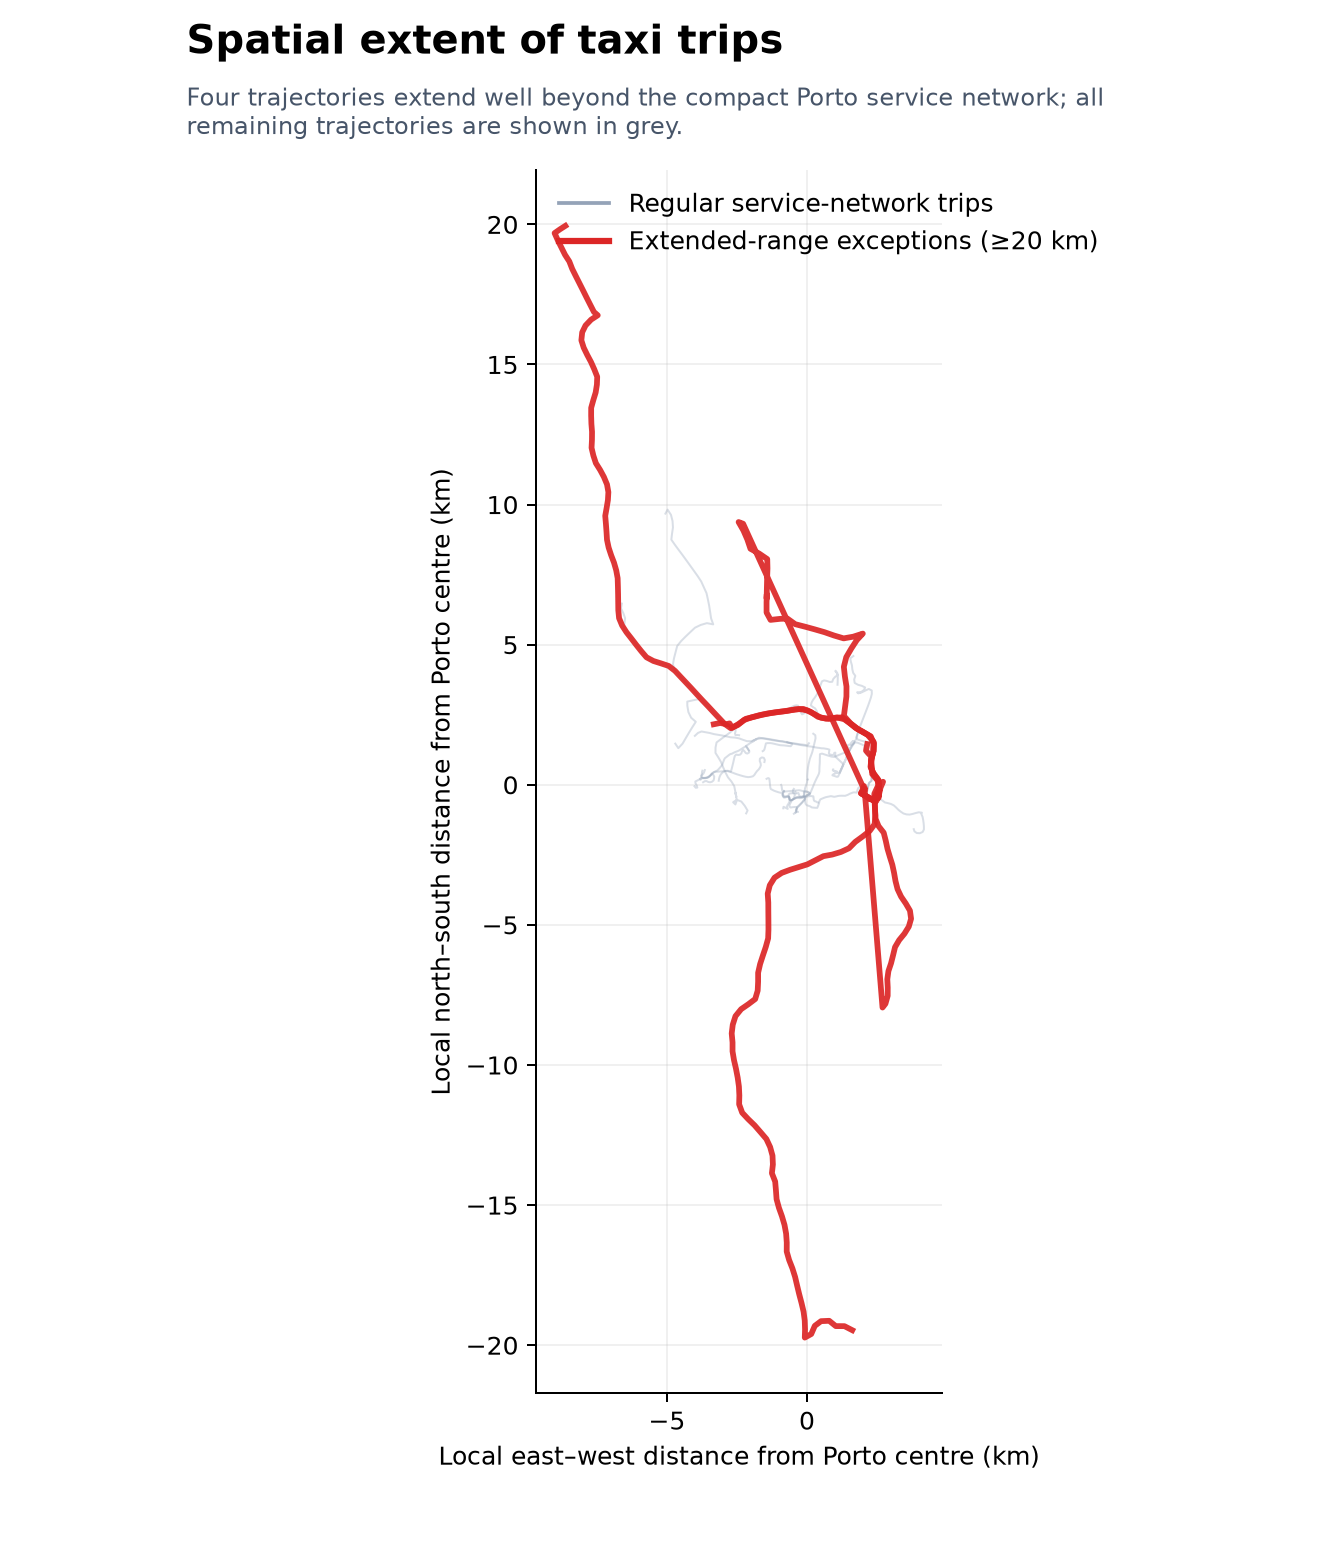

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

d = df.copy()
long = d[d.distance_km >= 20]
plt.scatter(d.start_lon, d.start_lat, c=(d.distance_km >= 20), cmap="Reds")
plt.xlabel("start longitude")
plt.ylabel("start latitude")
print(long[["trajectory_id", "distance_km"]])
plt.close("all")
# Display the verified visualization once.
display(Image(filename="visualizations/spatial_extent_exceptions.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Low (2 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "spatial_extent_exception",
  "insight": "Most selected trips remain within the dominant Porto service network, while a small number extend much farther toward the metropolitan edges.",
  "insight_value": {
    "extended_range_threshold_km": 20,
    "extended_range_trips": 4
  },
  "plot": {
    "plot_type": "highlighted_trajectory_map",
    "title": "Spatial Extent of Taxi Trips",
    "file": "visualizations/spatial_extent_exceptions.png",
    "description": "Grey lines show the compact service-network trips; red lines identify the four trajectories whose observed distance exceeds 20 km."
  },
  "question": "Which trajectories extend beyond the spatial footprint of the dominant Porto taxi service network?",
  "actionable_insight": "Use route extent to distinguish metropolitan-edge trips from the compact service-network pattern.",
  "code": "import pandas as pd\nimport matplotlib.pyplot as plt\nd=df.copy(); long=d[d.distance_km>=20]\nplt.scatter(d.start_lon,d.start_lat,c=(d.distance_km>=20),cmap='Reds'); plt.xlabel('start longitude'); plt.ylabel('start latitude'); print(long[['trajectory_id','distance_km']])",
  "insight_type": "exception_deviation",
  "difficulty_level": 2,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "gps_position",
    "trajectory_id"
  ]
}

### **Question 2**: Which completed trips are unusually short or nearly stationary, based on elapsed duration and distance travelled?

#### Analysis action

Separate extremely short-duration, near-stationary movement records from spatially extended trips before interpreting service anomalies.

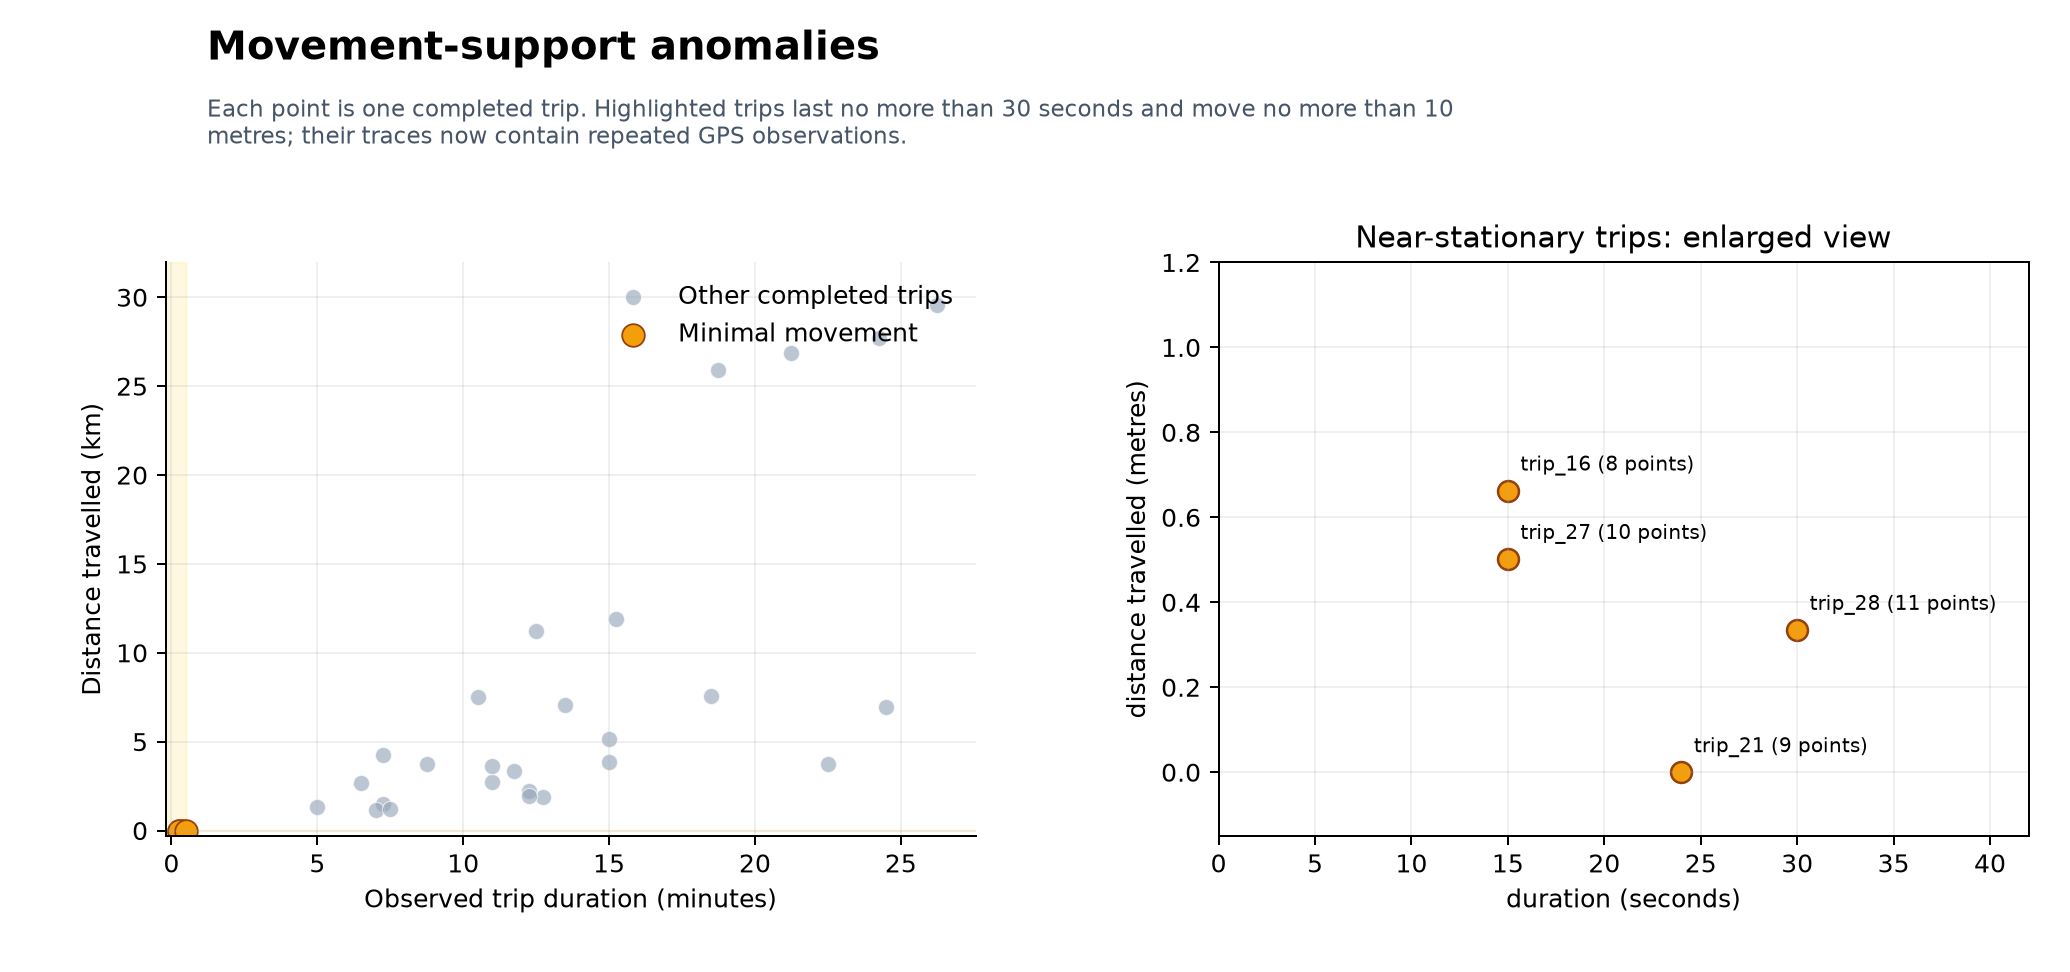

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

d = df.copy()
d["minimal_movement"] = (d.duration_seconds <= 30) & (d.distance_km <= 0.01)
plt.scatter(
    d.duration_seconds / 60,
    d.distance_km,
    c=d.minimal_movement.map({True: "#f59e0b", False: "#94a3b8"}),
)
plt.xlabel("duration (minutes)")
plt.ylabel("distance travelled (km)")
print(
    d[d.minimal_movement][
        ["trajectory_id", "duration_seconds", "distance_km", "point_count"]
    ]
)
plt.close("all")
# Display the verified visualization once.
display(Image(filename="visualizations/movement_support_exceptions.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Low (3 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "movement_support_exception",
  "insight": "Very short or nearly stationary completed trips form a distinct exception to the longer moving trips and need to be interpreted separately from ordinary city crossings.",
  "insight_value": {
    "duration_threshold_seconds": 30,
    "distance_threshold_km": 0.01,
    "minimal_movement_trips": 4
  },
  "plot": {
    "plot_type": "duration_distance_scatter_with_zoom",
    "title": "Movement-Support Anomalies",
    "file": "visualizations/movement_support_exceptions.png",
    "description": "Trip duration and travelled distance identify near-stationary trips; the enlarged panel shows their sub-metre movement and GPS sample counts."
  },
  "question": "Which completed trips are unusually short or nearly stationary, based on elapsed duration and distance travelled?",
  "actionable_insight": "Separate extremely short-duration, near-stationary movement records from spatially extended trips before interpreting service anomalies.",
  "code": "import pandas as pd\nimport matplotlib.pyplot as plt\nd=df.copy(); d['minimal_movement']=(d.duration_seconds<=30)&(d.distance_km<=.01)\nplt.scatter(d.duration_seconds/60,d.distance_km,c=d.minimal_movement.map({True:'#f59e0b',False:'#94a3b8'})); plt.xlabel('duration (minutes)'); plt.ylabel('distance travelled (km)'); print(d[d.minimal_movement][['trajectory_id','duration_seconds','distance_km','point_count']])",
  "insight_type": "exception_deviation",
  "difficulty_level": 3,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "gps_position",
    "trajectory_id",
    "trajectory_timestamp"
  ]
}

### **Question 3**: How do pickup channels differ between extended-range and minimal-movement exceptions?

#### Analysis action

Compare anomaly type with pickup channel to avoid treating all exceptional trips as one service-context phenomenon.

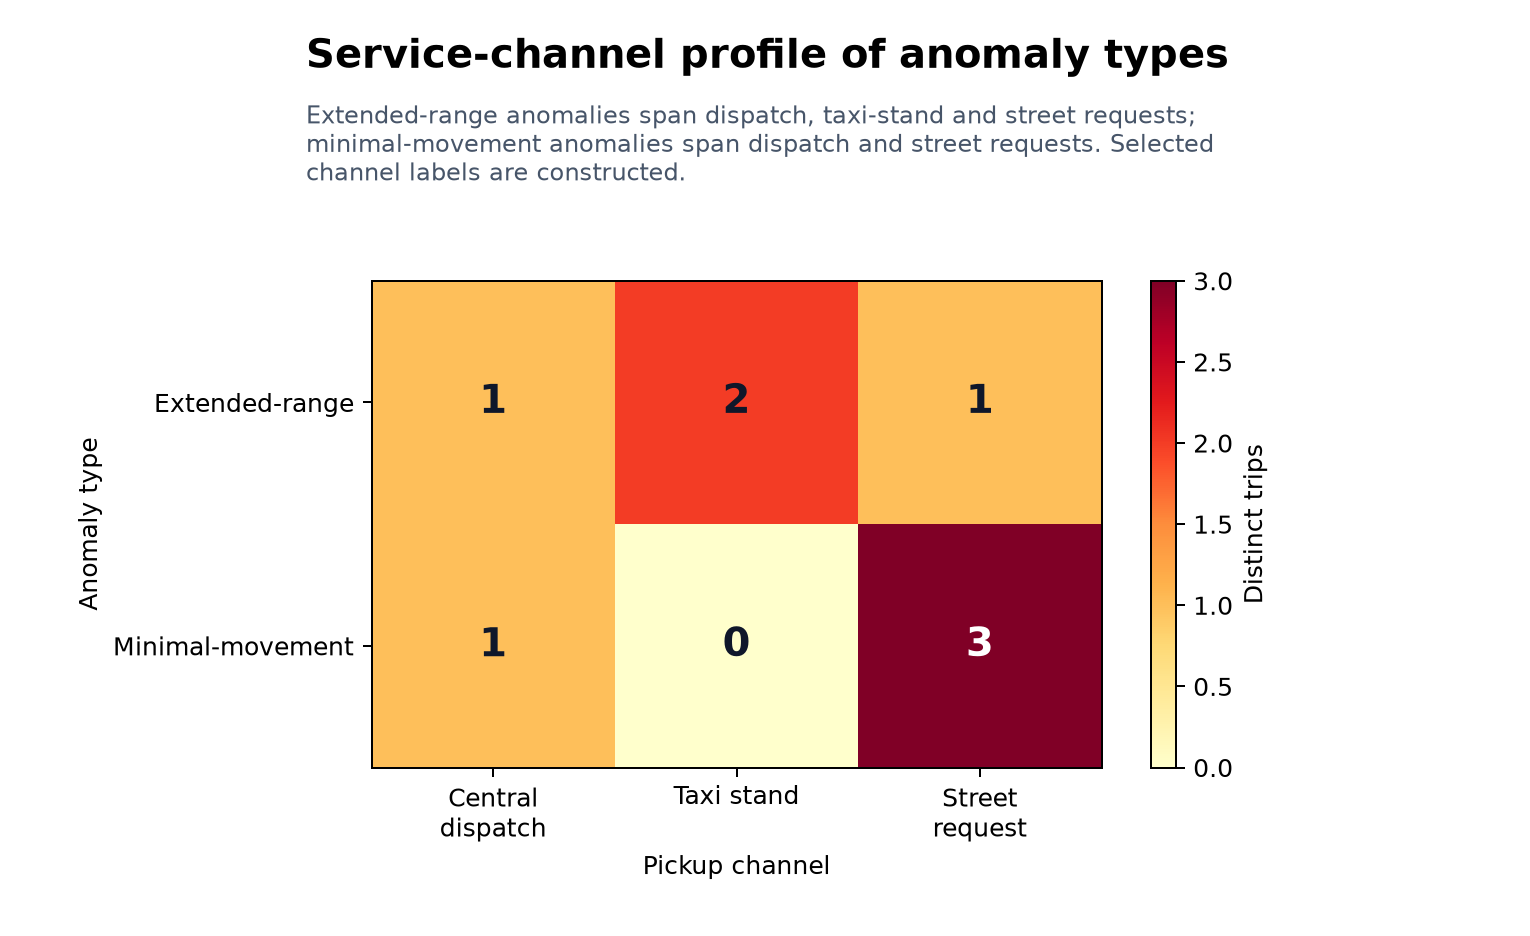

In [ ]:
import pandas as pd

d = df.copy()
d["anomaly_type"] = "regular"
d.loc[d.distance_km >= 20, "anomaly_type"] = "extended-range"
d.loc[(d.duration_seconds <= 30) & (d.distance_km <= 0.01), "anomaly_type"] = (
    "minimal-movement"
)
print(
    pd.crosstab(
        d[d.anomaly_type != "regular"].anomaly_type,
        d[d.anomaly_type != "regular"].call_type,
    )
)
plt.close("all")
# Display the verified visualization once.
display(Image(filename="visualizations/anomaly_channel_heatmap.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "anomaly_service_context",
  "insight": "The exceptional trips are not confined to one pickup channel: unusual spatial extent and unusual local movement both occur across different service contexts.",
  "insight_value": {
    "extended_range": {
      "central_dispatch": 1,
      "taxi_stand": 2,
      "street_request": 1
    },
    "minimal_movement": {
      "central_dispatch": 1,
      "street_request": 3
    }
  },
  "plot": {
    "plot_type": "anomaly_channel_heatmap",
    "title": "Service-Channel Profile of Anomaly Types",
    "file": "visualizations/anomaly_channel_heatmap.png",
    "description": "The heatmap cross-tabulates anomaly type and pickup channel for distinct trips, rather than reusing the spatial map."
  },
  "question": "How do pickup channels differ between extended-range and minimal-movement exceptions?",
  "actionable_insight": "Compare anomaly type with pickup channel to avoid treating all exceptional trips as one service-context phenomenon.",
  "code": "import pandas as pd\nd=df.copy(); d['anomaly_type']='regular'; d.loc[d.distance_km>=20,'anomaly_type']='extended-range'; d.loc[(d.duration_seconds<=30)&(d.distance_km<=.01),'anomaly_type']='minimal-movement'; print(pd.crosstab(d[d.anomaly_type!='regular'].anomaly_type,d[d.anomaly_type!='regular'].call_type))",
  "insight_type": "exception_deviation",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "gps_position",
    "request_source",
    "trajectory_id",
    "trajectory_timestamp"
  ]
}

### Summary of Findings (Flag 2)

Most selected trips remain within the dominant Porto service network, while a small number extend to metropolitan edges. Very short or nearly stationary completed trips form a separate exception to longer moving trips. Together, the exception types occur across more than one pickup channel and therefore represent different service contexts.